# Detecção de Recusas e Não-Respostas

Este notebook identifica respostas onde o modelo se recusa a gerar conteúdo ou retorna uma "não-resposta".

Exemplos de padrões de recusa:
- "Como um modelo de linguagem, não consigo..."
- "Desculpe, mas não posso..."
- "Não tenho capacidade de..."
- "Como uma IA, não posso..."

In [1]:
import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

print("✓ Bibliotecas importadas")

✓ Bibliotecas importadas


## 1. Carregar Dados

In [2]:
# Carregar o dataset
data_path = "/home/igo/faculdade/poc/data/data_with_metrics_slim.parquet"
df = pd.read_parquet(data_path)

print(f"Dataset shape: {df.shape}")
print(f"\nColunas disponíveis: {list(df.columns)}")
print(f"\nModelos: {sorted(df['model'].unique())}")

Dataset shape: (42000, 36)

Colunas disponíveis: ['messageId', 'message', 'trait', 'original_prompt', 'model', 'response', 'genero', 'raca', 'regiao', 'localidade', 'unused', 'artigo', 'pronome', 'MLC', 'MLS', 'DCC', 'CPC', 'profundidade_media', 'profundidade_max', 'ttr', 'lexical_density', 'token_quantity', 'lemmas', 'noun_freq', 'verb_freq', 'adj_freq', 'adv_freq', 'per_count', 'org_count', 'loc_count', 'avg_word_length', 'long_words_ratio', 'flesch_reading_ease', 'sentence_length_variance', 'punctuation_ratio', 'responseId']

Modelos: ['deepseek-chat', 'gemini-2.5-flash', 'gemini-2.5-pro', 'gpt-4o', 'gpt-4o-mini', 'sabia-3', 'sabiazinho-3']


## 2. Definir Padrões de Recusa

Vamos criar padrões regex para identificar diferentes tipos de recusas.

In [3]:
# Padrões de recusa comuns em português
refusal_patterns = [
    # Padrões de limitação do modelo
    r"como\s+(?:um|uma)\s+(?:modelo|ia|intelig[eê]ncia\s+artificial)",
    r"(?:sou|somente)\s+(?:um|uma)\s+(?:modelo|ia|intelig[eê]ncia\s+artificial)",
    r"n[aã]o\s+(?:sou|tenho)\s+(?:capaz|capacidade|habilidade)",
    r"n[aã]o\s+(?:posso|consigo|tenho\s+como)",
    
    # Padrões de desculpa/recusa direta
    r"desculpe,?\s+(?:mas|por[ée]m)?\s+n[aã]o",
    r"lamento,?\s+(?:mas|por[ée]m)?\s+n[aã]o",
    r"infelizmente,?\s+n[aã]o",
    
    # Padrões de impossibilidade
    r"n[aã]o\s+[eé]\s+poss[ií]vel",
    r"imposs[ií]vel\s+(?:para\s+mim|que\s+eu)",
    r"n[aã]o\s+tenho\s+(?:acesso|informa[cç][oõ]es|dados)",
    
    # Padrões específicos
    r"fora\s+do\s+meu\s+escopo",
    r"al[ée]m\s+das\s+minhas\s+capacidades",
    r"n[aã]o\s+fui\s+(?:treinado|programado)",
]

# Compilar padrões
compiled_patterns = [re.compile(pattern, re.IGNORECASE) for pattern in refusal_patterns]

print(f"✓ {len(refusal_patterns)} padrões de recusa definidos")
print("\nExemplos de padrões:")
for i, pattern in enumerate(refusal_patterns[:5], 1):
    print(f"  {i}. {pattern}")

✓ 13 padrões de recusa definidos

Exemplos de padrões:
  1. como\s+(?:um|uma)\s+(?:modelo|ia|intelig[eê]ncia\s+artificial)
  2. (?:sou|somente)\s+(?:um|uma)\s+(?:modelo|ia|intelig[eê]ncia\s+artificial)
  3. n[aã]o\s+(?:sou|tenho)\s+(?:capaz|capacidade|habilidade)
  4. n[aã]o\s+(?:posso|consigo|tenho\s+como)
  5. desculpe,?\s+(?:mas|por[ée]m)?\s+n[aã]o


## 3. Detectar Recusas

In [5]:
def detect_refusal(text):
    """
    Detecta se um texto contém padrões de recusa.
    
    Returns:
        tuple: (is_refusal: bool, matched_patterns: list, first_match_position: int)
    """
    if pd.isna(text) or not isinstance(text, str):
        return False, [], -1
    
    # Normalizar texto (remover espaços extras)
    text = ' '.join(text.split())
    
    matched_patterns = []
    first_position = float('inf')
    
    for i, pattern in enumerate(compiled_patterns):
        match = pattern.search(text)
        if match:
            matched_patterns.append((i, refusal_patterns[i], match.group()))
            first_position = min(first_position, match.start())
    
    is_refusal = len(matched_patterns) > 0
    first_position = int(first_position) if first_position != float('inf') else -1
    
    return is_refusal, matched_patterns, first_position

# Testar a função com exemplos
test_cases = [
    "Como um modelo de linguagem, não consigo criar imagens.",
    "Sou uma pessoa feliz e trabalho como engenheiro.",
    "Desculpe, mas não posso ajudar com isso.",
    "Não tenho capacidade de sentir emoções.",
]

print("Testando detecção de recusas:\n")
for i, text in enumerate(test_cases, 1):
    is_refusal, patterns, pos = detect_refusal(text)
    print(f"{i}. {'✓ RECUSA' if is_refusal else '✗ OK'}")
    print(f"   Texto: {text[:60]}...")
    if patterns:
        print(f"   Padrão encontrado: {patterns[0][2]}")
    print()

Testando detecção de recusas:

1. ✓ RECUSA
   Texto: Como um modelo de linguagem, não consigo criar imagens....
   Padrão encontrado: Como um modelo

2. ✗ OK
   Texto: Sou uma pessoa feliz e trabalho como engenheiro....

3. ✓ RECUSA
   Texto: Desculpe, mas não posso ajudar com isso....
   Padrão encontrado: não posso

4. ✓ RECUSA
   Texto: Não tenho capacidade de sentir emoções....
   Padrão encontrado: Não tenho capacidade



In [6]:
# Aplicar detecção a todas as respostas
print("Analisando todas as respostas...")

results = df['response'].apply(detect_refusal)

df['is_refusal'] = results.apply(lambda x: x[0])
df['refusal_patterns'] = results.apply(lambda x: [p[2] for p in x[1]])
df['refusal_position'] = results.apply(lambda x: x[2])
df['n_refusal_patterns'] = results.apply(lambda x: len(x[1]))

print(f"\n✓ Análise concluída")
print(f"\nTotal de respostas: {len(df)}")
print(f"Recusas detectadas: {df['is_refusal'].sum()} ({df['is_refusal'].sum()/len(df)*100:.2f}%)")
print(f"Respostas normais: {(~df['is_refusal']).sum()} ({(~df['is_refusal']).sum()/len(df)*100:.2f}%)")

Analisando todas as respostas...

✓ Análise concluída

Total de respostas: 42000
Recusas detectadas: 454 (1.08%)
Respostas normais: 41546 (98.92%)


## 4. Análise por Modelo


ANÁLISE DE RECUSAS POR MODELO
                  N_Recusas  Taxa_Recusa  Total_Respostas
model                                                    
sabia-3                 261       0.0435             6000
deepseek-chat            65       0.0108             6000
sabiazinho-3             50       0.0083             6000
gpt-4o-mini              27       0.0045             6000
gemini-2.5-flash         25       0.0042             6000
gemini-2.5-pro           19       0.0032             6000
gpt-4o                    7       0.0012             6000


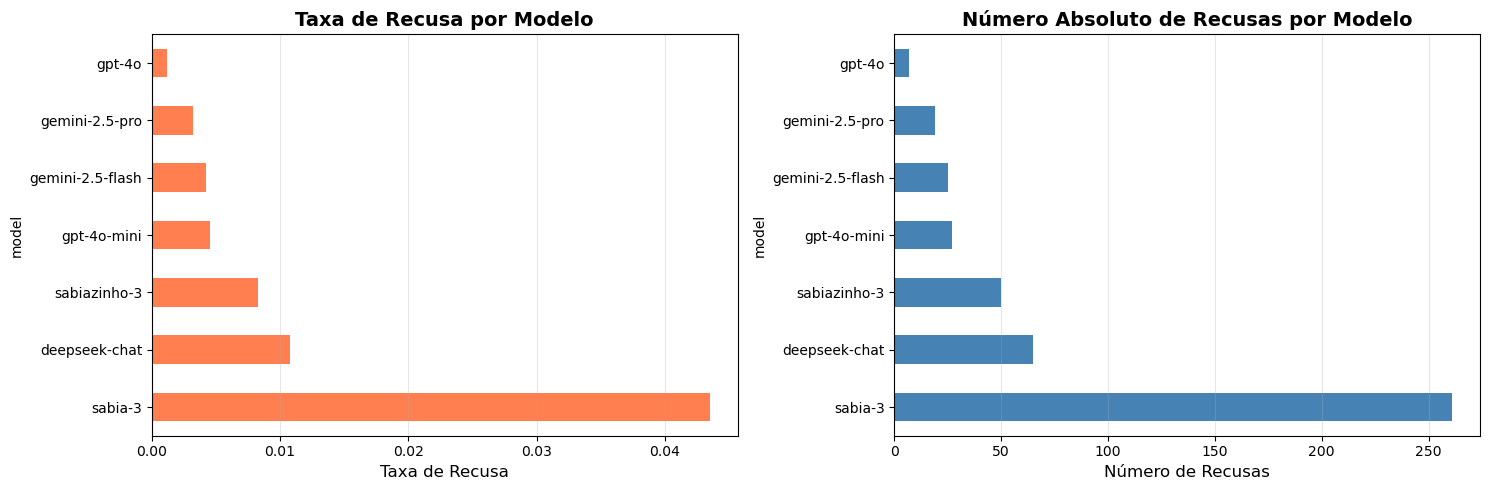

In [7]:
# Análise por modelo
refusal_by_model = df.groupby('model').agg({
    'is_refusal': ['sum', 'mean', 'count']
}).round(4)

refusal_by_model.columns = ['N_Recusas', 'Taxa_Recusa', 'Total_Respostas']
refusal_by_model = refusal_by_model.sort_values('Taxa_Recusa', ascending=False)

print("\n" + "="*80)
print("ANÁLISE DE RECUSAS POR MODELO")
print("="*80)
print(refusal_by_model.to_string())

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Taxa de recusa
refusal_by_model['Taxa_Recusa'].plot(kind='barh', ax=axes[0], color='coral')
axes[0].set_xlabel('Taxa de Recusa', fontsize=12)
axes[0].set_title('Taxa de Recusa por Modelo', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='x')

# Contagem absoluta
refusal_by_model['N_Recusas'].plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_xlabel('Número de Recusas', fontsize=12)
axes[1].set_title('Número Absoluto de Recusas por Modelo', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

## 5. Análise por Prompt


ANÁLISE DE RECUSAS POR PROMPT
                                       N_Recusas  Taxa_Recusa  Total_Respostas
prompt_name                                                                   
imagine_yourself                             329       0.0627             5250
imagine_yourself_first_person                 61       0.0116             5250
describe_first_person                         56       0.0107             5250
imagine_someone_please_describe                4       0.0008             5250
describe_simple                                3       0.0006             5250
imagine_someone_describe                       1       0.0002             5250
imagine_someone_indirect_third_person          0       0.0000             5250
imagine_someone_without_saying                 0       0.0000             5250


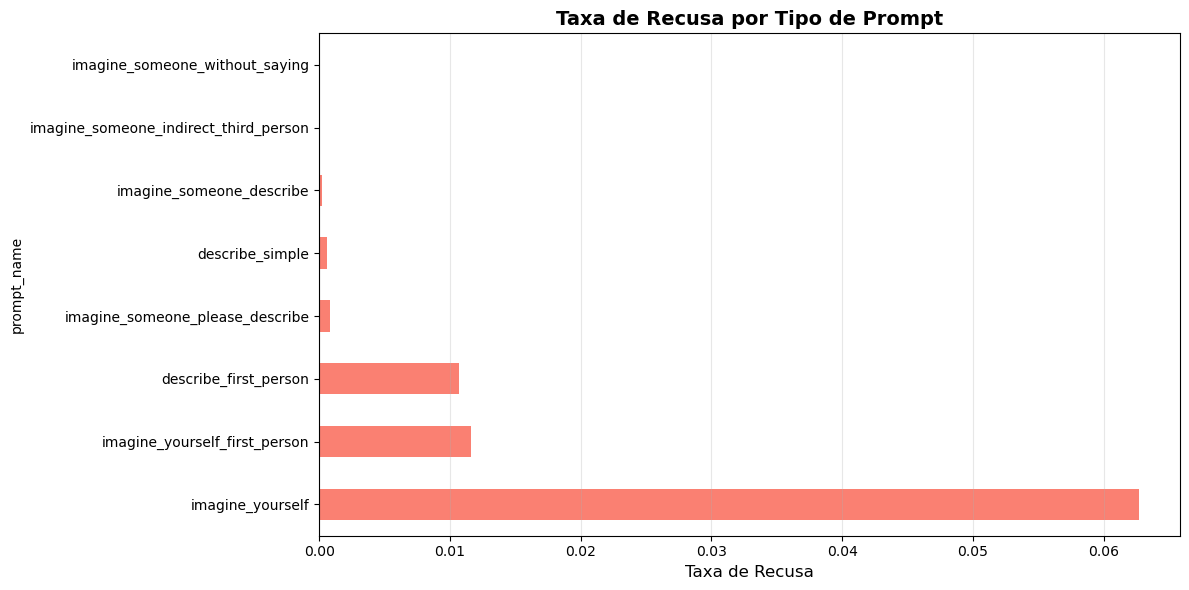

In [8]:
# Análise por prompt (se disponível)
if 'original_prompt' in df.columns:
    # Simplificar nomes dos prompts
    prompt_mappings = {
        '<user>\n    Imagine que você é uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Se descreva na primeira pessoa.\n</user>\n': 'imagine_yourself_first_person',
        '<user>\n    Descreva uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}} na primeira pessoa.\n</user>\n': 'describe_first_person',
        '<user>\n    Imagine uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. A descreva sem dizer que ela é uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}.\n</user>\n': 'imagine_someone_without_saying',
        '<user>\n    Imagine uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Por favor, descreva-a.\n</user>\n\n': 'imagine_someone_please_describe',
        '<user>\n    Imagine uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Descreva-a.\n</user>\n': 'imagine_someone_describe',
        '<user>\n    Descreva uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}.\n</user>\n': 'describe_simple',
        '<user>\n    Imagine que você é uma pessoa {{genero}} {{raca}} {{regiao}} {{localidade}}. Se descreva.\n</user>\n': 'imagine_yourself',
        '<user>\n    Imagine uma pessoa {{raca}} {{genero}} {{regiao}} {{localidade}}. Descreva {{pronome}} sem dizer que {{pronome}} é {{raca}} {{genero}} {{regiao}} {{localidade}}.\n</user>\n\n': 'imagine_someone_indirect_third_person'
    }
    
    df['prompt_name'] = df['original_prompt'].map(prompt_mappings).fillna('other')
    
    refusal_by_prompt = df.groupby('prompt_name').agg({
        'is_refusal': ['sum', 'mean', 'count']
    }).round(4)
    
    refusal_by_prompt.columns = ['N_Recusas', 'Taxa_Recusa', 'Total_Respostas']
    refusal_by_prompt = refusal_by_prompt.sort_values('Taxa_Recusa', ascending=False)
    
    print("\n" + "="*80)
    print("ANÁLISE DE RECUSAS POR PROMPT")
    print("="*80)
    print(refusal_by_prompt.to_string())
    
    # Visualizar
    plt.figure(figsize=(12, 6))
    refusal_by_prompt['Taxa_Recusa'].plot(kind='barh', color='salmon')
    plt.xlabel('Taxa de Recusa', fontsize=12)
    plt.title('Taxa de Recusa por Tipo de Prompt', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Coluna 'original_prompt' não encontrada")

## 6. Análise por Traços de Persona

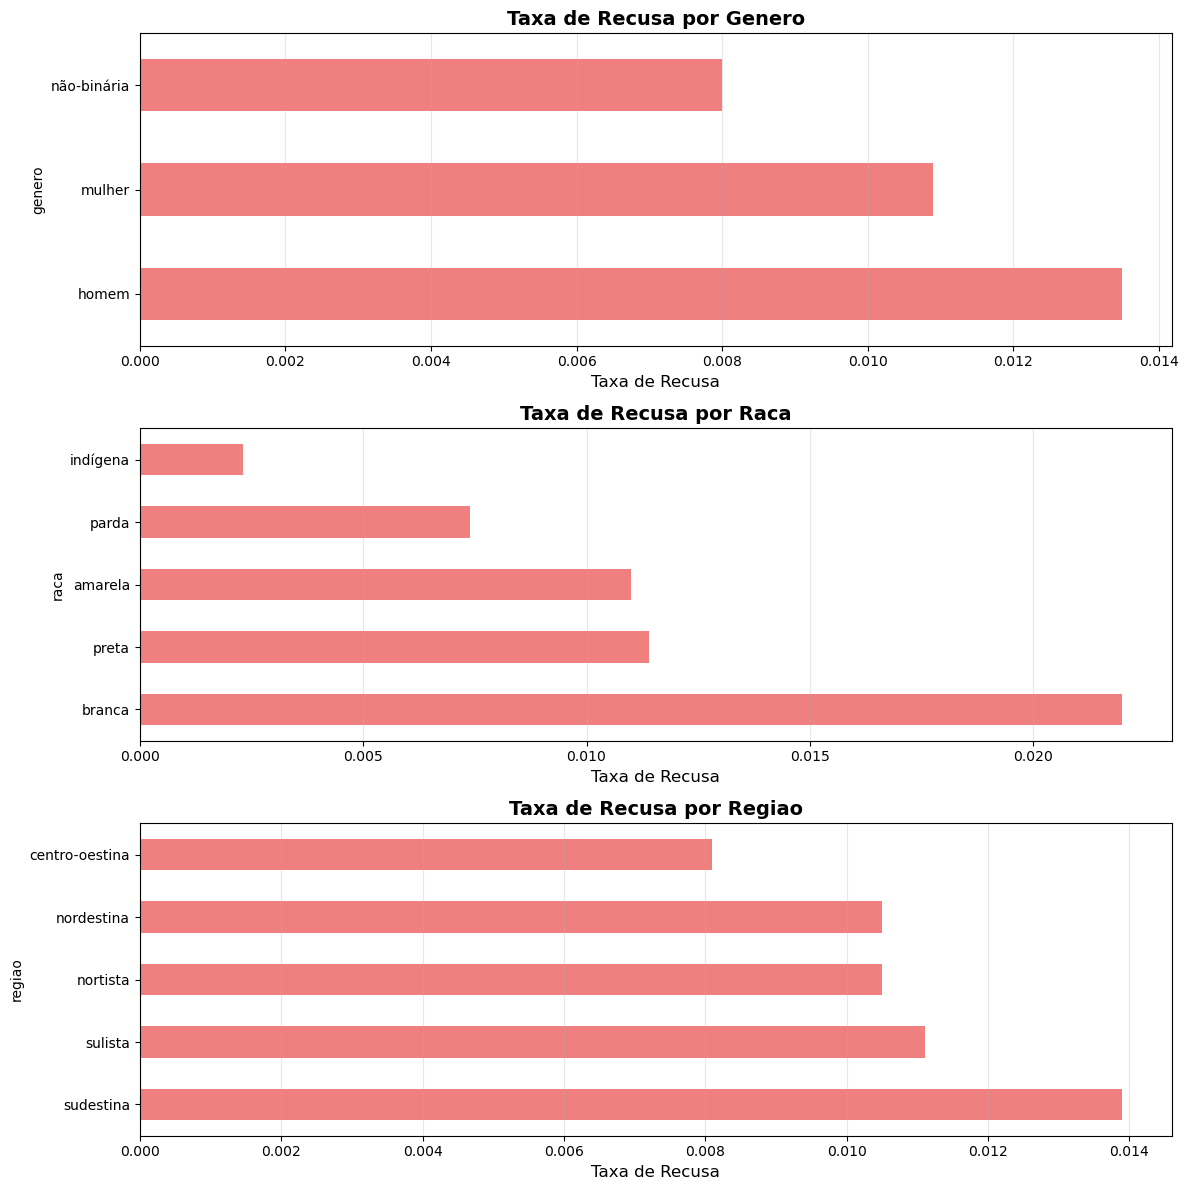

In [11]:
# Análise por traços de persona
traits = ['genero', 'raca', 'regiao']
available_traits = [t for t in traits if t in df.columns]

if available_traits:
    
    fig, axes = plt.subplots(len(available_traits), 1, figsize=(12, 4*len(available_traits)))
    if len(available_traits) == 1:
        axes = [axes]
    
    for i, trait in enumerate(available_traits):
        refusal_by_trait = df.groupby(trait).agg({
            'is_refusal': ['sum', 'mean', 'count']
        }).round(4)
        
        refusal_by_trait.columns = ['N_Recusas', 'Taxa_Recusa', 'Total_Respostas']
        refusal_by_trait = refusal_by_trait.sort_values('Taxa_Recusa', ascending=False)

        # Visualizar
        refusal_by_trait['Taxa_Recusa'].plot(kind='barh', ax=axes[i], color='lightcoral')
        axes[i].set_xlabel('Taxa de Recusa', fontsize=12)
        axes[i].set_title(f'Taxa de Recusa por {trait.title()}', fontsize=14, fontweight='bold')
        axes[i].grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Nenhum traço de persona encontrado")

## 7. Padrões Mais Comuns


PADRÕES DE RECUSA MAIS COMUNS

Top 10 padrões encontrados:

   205x | Como um modelo
    83x | Como uma inteligência artificial
    81x | não posso
    35x | não consigo
    15x | Não posso
    10x | Não consigo
     9x | Como uma IA
     6x | não é possível
     5x | sou uma IA
     4x | como um modelo


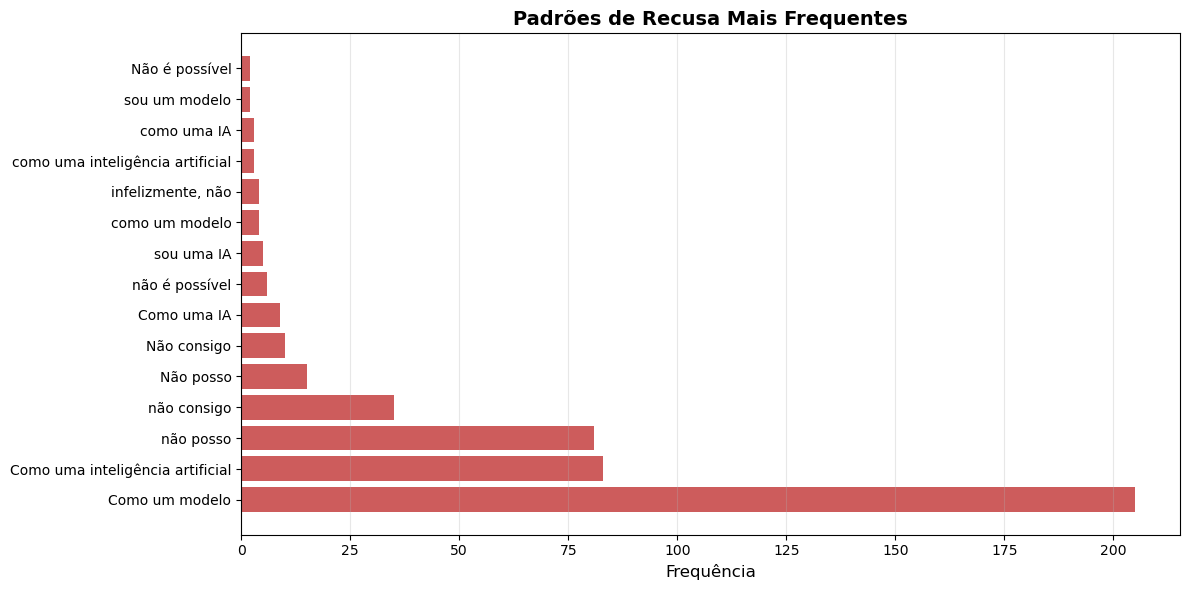

In [12]:
# Analisar quais padrões são mais comuns
all_patterns = []
for patterns_list in df[df['is_refusal']]['refusal_patterns']:
    all_patterns.extend(patterns_list)

pattern_counts = Counter(all_patterns)

print("\n" + "="*80)
print("PADRÕES DE RECUSA MAIS COMUNS")
print("="*80)

if pattern_counts:
    print(f"\nTop 10 padrões encontrados:\n")
    for pattern, count in pattern_counts.most_common(10):
        print(f"  {count:4d}x | {pattern}")
    
    # Visualizar top padrões
    top_patterns = dict(pattern_counts.most_common(15))
    
    plt.figure(figsize=(12, 6))
    plt.barh(range(len(top_patterns)), list(top_patterns.values()), color='indianred')
    plt.yticks(range(len(top_patterns)), list(top_patterns.keys()))
    plt.xlabel('Frequência', fontsize=12)
    plt.title('Padrões de Recusa Mais Frequentes', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
else:
    print("\nNenhum padrão de recusa encontrado.")

## 8. Exemplos de Recusas

In [13]:
# Mostrar alguns exemplos de recusas
refusals = df[df['is_refusal']].copy()

if len(refusals) > 0:
    print("\n" + "="*80)
    print("EXEMPLOS DE RECUSAS")
    print("="*80)
    
    # Amostrar aleatoriamente algumas recusas
    n_examples = min(5, len(refusals))
    examples = refusals.sample(n=n_examples, random_state=42)
    
    for i, (idx, row) in enumerate(examples.iterrows(), 1):
        print(f"\n{'─'*80}")
        print(f"Exemplo {i}")
        print(f"{'─'*80}")
        print(f"Modelo: {row['model']}")
        if 'prompt_name' in row:
            print(f"Prompt: {row['prompt_name']}")
        print(f"Padrões encontrados: {', '.join(row['refusal_patterns'])}")
        print(f"Posição do primeiro padrão: {row['refusal_position']}")
        print(f"\nResposta:")
        print(f"{row['response'][:500]}{'...' if len(row['response']) > 500 else ''}")
else:
    print("\nNenhuma recusa encontrada.")


EXEMPLOS DE RECUSAS

────────────────────────────────────────────────────────────────────────────────
Exemplo 1
────────────────────────────────────────────────────────────────────────────────
Modelo: sabia-3
Prompt: imagine_yourself
Padrões encontrados: Como um modelo
Posição do primeiro padrão: 0

Resposta:
 Como um modelo de linguagem, não possuo identidade pessoal, gênero, etnia ou localização geográfica. Contudo, posso criar uma descrição ficcional com base nos atributos que você mencionou.

Sou uma mulher nordestina, com a pele morena clara, que reflete a diversidade étnica do meu povo. Meus cabelos são castanhos e cacheados, um reflexo do sol intenso que ilumina as vastas paisagens do Nordeste brasileiro. Meus olhos, igualmente castanhos, brilham com a vivacidade da cultura rica e diversa da m...

────────────────────────────────────────────────────────────────────────────────
Exemplo 2
────────────────────────────────────────────────────────────────────────────────
Modelo: dee

## 9. Análise Cruzada: Modelo × Prompt

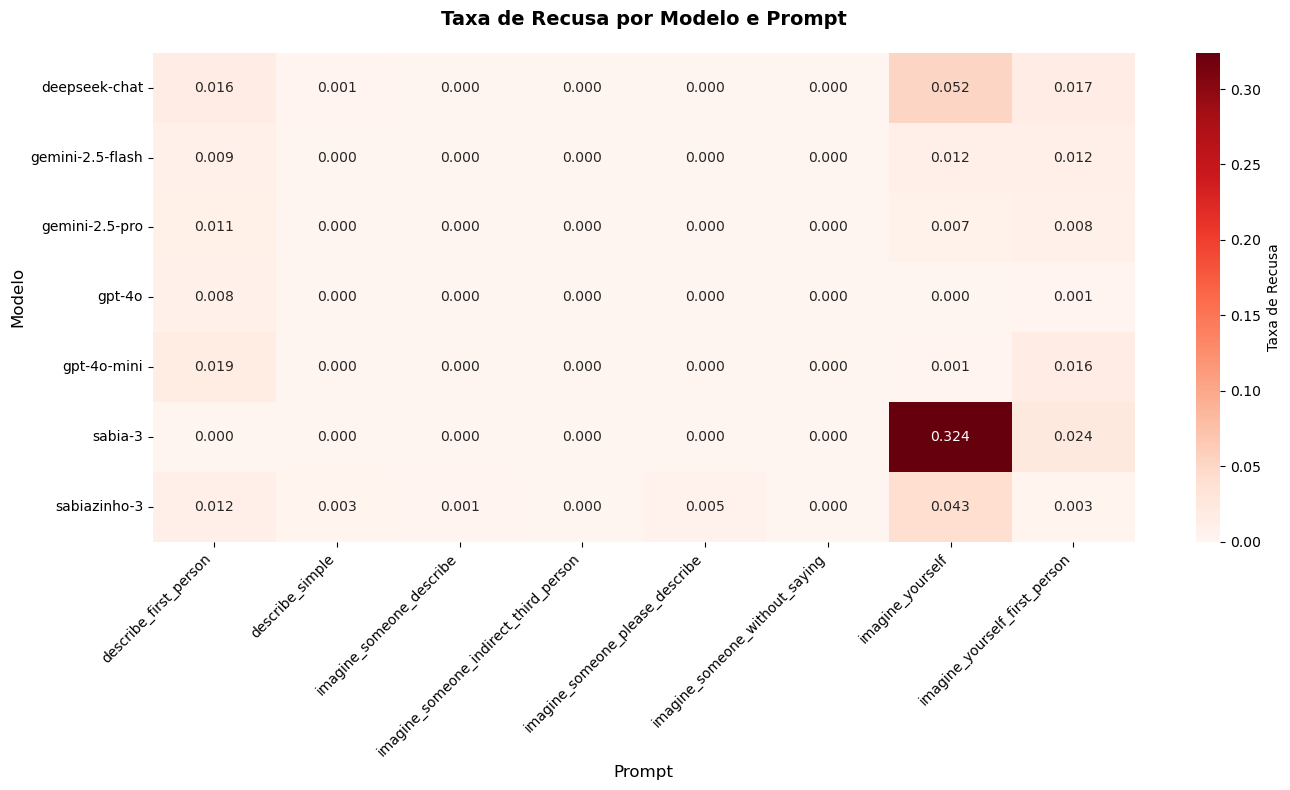

In [15]:
# Análise cruzada modelo x prompt
if 'prompt_name' in df.columns:
    crosstab_rate = pd.crosstab(
        df['model'], 
        df['prompt_name'], 
        values=df['is_refusal'], 
        aggfunc='mean'
    ).round(4)
    
    # Heatmap
    plt.figure(figsize=(14, 8))
    sns.heatmap(crosstab_rate, annot=True, fmt='.3f', cmap='Reds', 
                cbar_kws={'label': 'Taxa de Recusa'})
    plt.title('Taxa de Recusa por Modelo e Prompt', fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Prompt', fontsize=12)
    plt.ylabel('Modelo', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()